# Aula 03 — Vigilância Inteligente em Tempo Real: latência, throughput e FPS

**Disciplina: Engenharia de Machine Learning — FIAP PósTech**

---

## 🎯 Objetivo da aula

Nesta aula vamos entender, na prática, como **latência**, **throughput** e **FPS** impactam um sistema de visão computacional que precisa funcionar em **tempo real**.

Usaremos como exemplo o caso de um **sistema de vigilância inteligente** em um campus empresarial. Ao final, você será capaz de:

1. Entender o problema de latência em detecção de intrusos por câmeras.
2. Explicar de forma simples o que são **latência de inferência**, **throughput** e **FPS**.
3. Medir na prática a latência média e calcular os FPS de um pipeline de visão.
4. Comparar um modelo **pesado** com um modelo **otimizado**.
5. Avaliar se o sistema atende à meta de **30 FPS** (tempo real).
6. Discutir técnicas reais de otimização e seus trade-offs.

## ✅ Pré-requisitos

Antes de executar este notebook, garanta o seguinte:

### 1. Software necessário

| Item | Versão mínima | Observação |
|---|---|---|
| **Python** | 3.10+ | Verifique com `python --version` |
| **Jupyter** | 1.0+ | Para abrir e executar o notebook |
| **NumPy** | 1.24+ | Geração de ruído e estatísticas |
| **Pandas** | 2.0+ | Tabela comparativa |
| **Matplotlib** | 3.7+ | Visualizações |

Este notebook é **leve e autocontido**: usa apenas `numpy`, `pandas` e `matplotlib`. **Não requer GPU**, internet ou datasets externos — roda em qualquer ambiente local simples.

### 2. Instalação das dependências

**Opção A — no terminal (recomendado):**

```bash
# a partir da pasta 03_desafios_performance_visao_computacional
pip install -r requirements.txt

# ou, o mínimo para este notebook:
pip install numpy pandas matplotlib jupyter
```

**Opção B — direto no notebook:** execute a célula de instalação logo abaixo (descomente a linha `%pip install ...`).

### 3. Selecionar o kernel correto

No canto superior direito do notebook, clique em **"Select Kernel"** e escolha o interpretador Python onde as dependências foram instaladas. Se aparecer `ModuleNotFoundError`, quase sempre significa que o kernel selecionado não é o mesmo ambiente da instalação — selecione o kernel certo (ou rode a célula de instalação abaixo) e execute novamente.

In [3]:
# (Opcional) Instalar as dependencias diretamente no kernel atual.
# Descomente a linha abaixo caso veja "ModuleNotFoundError" ao rodar as proximas celulas.
%pip install numpy pandas matplotlib

# Verificacao rapida do ambiente
import sys
print("Python:", sys.version.split()[0])
try:
    import numpy, pandas, matplotlib
    print("numpy:", numpy.__version__)
    print("pandas:", pandas.__version__)
    print("matplotlib:", matplotlib.__version__)
    print("Dependencias OK. Pode seguir para a proxima celula.")
except ModuleNotFoundError as e:
    print("Faltando:", e.name)
    print("=> Descomente a linha '%pip install numpy pandas matplotlib' acima e rode esta celula novamente.")

   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------------------------------  9.7/9.8 MB 70.3 MB/s eta 0:00:01
   ---------------------------------------- 9.8/9.8 MB 61.5 MB/s  0:00:00

   ---------------------------------------- 0/2 [tzdata]
   ---------------------------------------- 0/2 [tzdata]
   ---------------------------------------- 0/2 [tzdata]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- --------------

## 1. Introdução: o sistema de vigilância inteligente

Imagine um **campus empresarial** com um sistema de vigilância inteligente. Câmeras de segurança usam IA para **detectar intrusos** e atividades suspeitas. O sistema opera **24 horas por dia** e precisa identificar ameaças **em tempo real**, alertando a equipe de segurança imediatamente.

Hoje o sistema usa um modelo robusto de visão computacional baseado em **ResNet-50**, com alta acurácia para análise de imagens.

### Características do cenário atual

| Item | Valor aproximado |
|---|---|
| Modelo | ResNet-50 |
| Parâmetros | ~25 milhões |
| Operações por imagem | ~4 bilhões |
| Latência média | ~200 ms por frame |
| Throughput | ~5 FPS |

### O problema

Uma latência de **200 ms por frame** gera um atraso perceptível na detecção de eventos críticos — como a presença de um intruso em área restrita. Para um sistema de segurança em tempo real, esse atraso pode ser **excessivo**: em 200 ms um intruso já se moveu, e o alerta chega tarde.

### O objetivo de negócio

O sistema precisa atingir aproximadamente **30 FPS**, ou seja:

- Processar cada frame em cerca de **33 ms**.
- Reduzir a latência de inferência.
- Aumentar o throughput.
- Manter precisão suficiente para diferenciar **funcionários autorizados** de **intrusos**.

```
📹 Câmera -> [captura frame] -> [modelo de IA] -> [decisão: intruso?] -> 🔔 alerta
```

> 🧩 A pergunta central da aula é: **o modelo consegue analisar cada frame rápido o suficiente para acompanhar o vídeo em tempo real?**

## 2. Conceitos principais

Antes do hands-on, três conceitos simples que amarram toda a aula.

### ⏱️ Latência de inferência

É o **tempo que o modelo leva para processar UM frame** (uma imagem), do momento em que ele entra até a decisão sair. Medida em milissegundos (ms). Quanto **menor**, melhor. No nosso caso: 200 ms é alto; queremos ~33 ms.

### 🚀 Throughput

É **quantos frames o sistema consegue processar por segundo**. Quanto **maior**, melhor. Se cada frame leva 200 ms, o sistema processa no máximo `1000 / 200 = 5` frames por segundo.

### 🎬 FPS (frames por segundo)

No contexto de vídeo, o throughput é medido em **FPS**. É essencialmente a mesma ideia: quantos quadros o sistema dá conta por segundo. Vídeo em tempo real costuma exigir **~30 FPS** para parecer fluido e não "perder" eventos.

### 🔗 A relação entre eles

Para um pipeline simples que processa um frame de cada vez, vale a relação:

$$\text{FPS} \approx \frac{1000}{\text{latência por frame (ms)}}$$

| Latência por frame | FPS aproximado | Tempo real (30 FPS)? |
|---|---|---|
| 200 ms | ~5 FPS | ❌ Não |
| 100 ms | ~10 FPS | ❌ Não |
| 33 ms | ~30 FPS | ✅ Sim |
| 16 ms | ~60 FPS | ✅ Sim |

### 🧮 Por que modelos grandes costumam ser mais lentos?

Modelos como a ResNet-50 têm **muitos parâmetros** (~25 milhões) e realizam **bilhões de operações** por imagem. Mais operações = mais tempo de cálculo = **maior latência**. Por isso, otimizar a inferência (modelo menor, quantização, hardware acelerado) é essencial em visão computacional em tempo real.

## 3. Hands-on prático

Vamos **simular** dois cenários de inferência e medir suas métricas. Em vez de rodar uma CNN real (que exigiria GPU e pesos treinados), simulamos o **tempo de inferência** de cada frame com `time.sleep()`. Assim o foco fica onde importa nesta aula: **medir latência, throughput e FPS**.

- **Cenário A — Modelo pesado:** ~200 ms por frame (semelhante à ResNet-50).
- **Cenário B — Modelo otimizado:** ~33 ms por frame (modelo menor + quantização).

Primeiro, os imports e a função de simulação que os dois cenários vão reutilizar.

In [4]:
# ------------------------------------------------------------------
# IMPORTS - enxutos para manter o notebook leve e sem GPU
# ------------------------------------------------------------------
import time                       # medir o tempo (latencia/throughput)
import numpy as np                # gerar o 'jitter' (ruido) e estatisticas
import pandas as pd               # montar a tabela comparativa
import matplotlib.pyplot as plt   # visualizar os resultados

# Semente fixa -> resultados reproduziveis (todos veem numeros parecidos).
np.random.seed(42)

# Meta de negocio: 30 FPS = tempo real.
META_FPS = 30
LATENCIA_ALVO_MS = 1000 / META_FPS   # ~33.3 ms por frame para bater a meta

print(f"Meta de tempo real: {META_FPS} FPS  (<= {LATENCIA_ALVO_MS:.1f} ms por frame)")
print("Ambiente pronto.")

Meta de tempo real: 30 FPS  (<= 33.3 ms por frame)
Ambiente pronto.


In [10]:
# ==================================================================
# FUNCAO DE SIMULACAO - o coracao do experimento
# ==================================================================
# OBJETIVO: imitar (simular) um sistema de visao processando frames de
# video, para conseguirmos MEDIR latencia, throughput e FPS.
#
# POR QUE SIMULAR em vez de usar um modelo real?
#   - Um modelo real (ResNet-50) precisaria de GPU, pesos treinados,
#     imagens de verdade e bibliotecas pesadas.
#   - Nesta aula o foco NAO e a acuracia do modelo, e sim ENTENDER as
#     metricas de performance. Entao substituimos a "inferencia real"
#     por um time.sleep(): dormir X ms "finge" que o modelo levou X ms
#     para analisar aquele frame. O relogio nao sabe a diferenca. :)
#
# IDEIA CENTRAL: se cada frame custa ~L milissegundos, quantos frames
# cabem em 1 segundo? Essa e a pergunta que a funcao responde medindo
# o tempo de verdade com o cronometro do computador.


def simular_pipeline_visao(latencia_media_ms, n_frames=30, jitter_ms=5.0):
    """Processa N frames (simulados) e devolve as metricas de performance.

    Parametros
    ----------
    latencia_media_ms : tempo MEDIO que "o modelo" leva por frame (ms).
                        Ex.: 200 = modelo pesado; 33 = modelo otimizado.
    n_frames          : quantos frames de video processar em sequencia.
                        Pense nisso como "quantas fotos a camera mandou".
    jitter_ms         : o quanto o tempo de cada frame VARIA aleatoriamente.
                        No mundo real nenhum frame leva exatamente o mesmo
                        tempo (cache, sistema operacional, etc.). O jitter
                        adiciona esse "ajuste" para ficar realista.

    Retorna
    -------
    dict com: n_frames, tempo_total_s, latencia_media_ms e fps.
    """
    # Lista onde vamos guardar a latencia REAL medida de cada frame (em ms).
    # No fim, a media dessa lista e a "latencia media por frame".
    latencias = []

    # ---- CRONOMETRO GERAL -------------------------------------------------
    # perf_counter() e um relogio de alta precisao (em segundos). Guardamos
    # o instante de INICIO do lote inteiro para, no final, saber quanto tempo
    # levou para processar TODOS os frames -> isso vira o FPS.
    inicio_total = time.perf_counter()

    # ---- LOOP: processa um frame de cada vez ------------------------------
    # Um pipeline simples analisa os frames em sequencia (um apos o outro).
    for _ in range(n_frames):
        # 1) Sortear quanto ESTE frame vai custar.
        #    np.random.normal(media, desvio) sorteia um numero em torno da
        #    latencia media. Ex.: media=200, jitter=8 -> normalmente entre
        #    ~184 e ~216 ms. Cada frame fica um pouco diferente (realismo).
        #    max(0.0, ...) e uma trava de seguranca: se o sorteio der um
        #    numero negativo, usamos 0 (tempo nunca pode ser negativo).
        atraso_ms = max(0.0, latencia_media_ms + np.random.normal(0, jitter_ms))

        # 2) Cronometrar o "processamento" deste unico frame.
        t0 = time.perf_counter()             # marca o inicio do frame
        time.sleep(atraso_ms / 1000.0)       # DORME atraso_ms (÷1000: ms -> s)
        t1 = time.perf_counter()             # marca o fim do frame
        # OBS: o time.sleep e o que "simula" o modelo trabalhando. Enquanto
        #      ele dorme, e como se a GPU/CPU estivesse calculando a resposta.

        # 3) Guardar a latencia REAL medida (t1 - t0), convertida de s para ms.
        #    Medimos o tempo de verdade (em vez de so confiar no atraso_ms)
        #    porque o sleep tem pequenas imprecisoes -> medir e mais honesto.
        latencias.append((t1 - t0) * 1000.0)

    # Instante de FIM do lote inteiro (todos os frames ja foram processados).
    fim_total = time.perf_counter()

    # ---- CALCULO DAS METRICAS --------------------------------------------
    # tempo_total_s: quanto tempo (em segundos) levou para processar tudo.
    tempo_total_s = fim_total - inicio_total

    # latencia_media_ms: media das latencias individuais -> "tempo tipico
    # por frame". E o numero que comparamos com a meta de ~33 ms.
    latencia_media = float(np.mean(latencias))

    # fps (frames por segundo): a metrica-chave de tempo real.
    # Formula: total de frames dividido pelo tempo total gasto.
    # Ex.: 30 frames em 6 s -> 5 FPS.  30 frames em 1 s -> 30 FPS.
    fps = n_frames / tempo_total_s

    # Devolvemos tudo num dicionario para as proximas celulas usarem/comparar.
    return {
        "n_frames": n_frames,
        "tempo_total_s": tempo_total_s,
        "latencia_media_ms": latencia_media,
        "fps": fps,
    }


print("Funcao 'simular_pipeline_visao' pronta para uso.")


Funcao 'simular_pipeline_visao' pronta para uso.


### Cenário A — Modelo pesado (ResNet-50)

Simulamos o sistema **atual**: cada frame leva cerca de **200 ms** para ser processado. Vamos rodar 30 frames (como se fosse ~1 segundo de vídeo a 30 FPS) e medir o que realmente acontece.

In [11]:
# Cenario A - modelo pesado (ResNet-50): ~200 ms por frame
res_a = simular_pipeline_visao(latencia_media_ms=200, n_frames=30, jitter_ms=8)

print("=== Cenario A - Modelo pesado (ResNet-50) ===")
print(f"Frames processados : {res_a['n_frames']}")
print(f"Tempo total        : {res_a['tempo_total_s']:.2f} s")
print(f"Latencia media     : {res_a['latencia_media_ms']:.1f} ms/frame")
print(f"FPS aproximado     : {res_a['fps']:.1f} FPS")

atende_a = res_a['fps'] >= META_FPS
print(f"Atinge {META_FPS} FPS (tempo real)? -> {'SIM' if atende_a else 'NAO'}")

=== Cenario A - Modelo pesado (ResNet-50) ===
Frames processados : 30
Tempo total        : 6.03 s
Latencia media     : 200.8 ms/frame
FPS aproximado     : 5.0 FPS
Atinge 30 FPS (tempo real)? -> NAO


Como esperado, com ~200 ms por frame o sistema fica **muito abaixo** dos 30 FPS (fica em torno de 5 FPS). Para a vigilância em tempo real, isso significa **atraso na detecção do intruso**.

### Cenário B — Modelo otimizado (MobileNet + quantização)

Agora simulamos uma versão **otimizada** do sistema: trocamos por um modelo mais leve (estilo MobileNet) e aplicamos quantização, chegando a cerca de **33 ms por frame**. Rodamos os **mesmos 30 frames** para comparar de forma justa.

In [13]:
# Cenario B - modelo otimizado: ~33 ms por frame
res_b = simular_pipeline_visao(latencia_media_ms=33, n_frames=30, jitter_ms=4)

print("=== Cenario B - Modelo otimizado (MobileNet + INT8) ===")
print(f"Frames processados : {res_b['n_frames']}")
print(f"Tempo total        : {res_b['tempo_total_s']:.2f} s")
print(f"Latencia media     : {res_b['latencia_media_ms']:.1f} ms/frame")
print(f"FPS aproximado     : {res_b['fps']:.1f} FPS")

atende_b = res_b['fps'] >= META_FPS
print(f"Atinge {META_FPS} FPS (tempo real)? -> {'SIM' if atende_b else 'NAO'}")

# Quanto mais rapido ficou o sistema otimizado em relacao ao pesado?
ganho = res_b['fps'] / res_a['fps']
print(f"\nO sistema otimizado ficou ~{ganho:.1f}x mais rapido que o original.")

=== Cenario B - Modelo otimizado (MobileNet + INT8) ===
Frames processados : 30
Tempo total        : 0.99 s
Latencia media     : 33.0 ms/frame
FPS aproximado     : 30.2 FPS
Atinge 30 FPS (tempo real)? -> SIM

O sistema otimizado ficou ~6.1x mais rapido que o original.


## 4. Comparação dos resultados

Vamos consolidar os dois cenários em uma **tabela** e, em seguida, em um **gráfico** para visualizar a diferença.

In [14]:
# Tabela comparativa dos dois cenarios
tabela = pd.DataFrame([
    {
        "Cenario": "A - ResNet-50 (pesado)",
        "Latencia media (ms)": round(res_a["latencia_media_ms"], 1),
        "FPS aproximado": round(res_a["fps"], 1),
        "Atende 30 FPS?": "Sim" if res_a["fps"] >= META_FPS else "Nao",
    },
    {
        "Cenario": "B - Otimizado (MobileNet+INT8)",
        "Latencia media (ms)": round(res_b["latencia_media_ms"], 1),
        "FPS aproximado": round(res_b["fps"], 1),
        "Atende 30 FPS?": "Sim" if res_b["fps"] >= META_FPS else "Nao",
    },
])
tabela

,Cenario,Latencia media (ms),FPS aproximado,Atende 30 FPS?
0,A - ResNet-50 (pesado),200.8,5.0,Nao
1,B - Otimizado (MobileNet+INT8),33.0,30.2,Sim


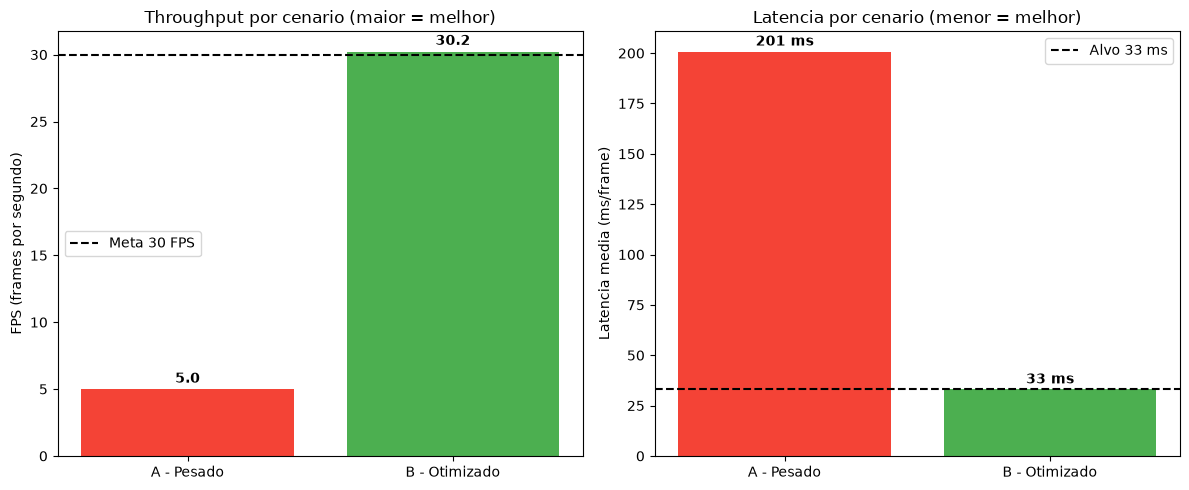

In [15]:
# Grafico comparativo: FPS e Latencia lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cenarios = ["A - Pesado", "B - Otimizado"]
fps_vals = [res_a["fps"], res_b["fps"]]
lat_vals = [res_a["latencia_media_ms"], res_b["latencia_media_ms"]]
cores = ["#F44336", "#4CAF50"]  # vermelho = ruim, verde = bom

# Grafico 1: FPS (quanto MAIOR, melhor). Linha tracejada = meta de 30 FPS.
axes[0].bar(cenarios, fps_vals, color=cores)
axes[0].axhline(META_FPS, color="black", linestyle="--", label=f"Meta {META_FPS} FPS")
axes[0].set_ylabel("FPS (frames por segundo)")
axes[0].set_title("Throughput por cenario (maior = melhor)")
axes[0].legend()
for i, v in enumerate(fps_vals):
    axes[0].text(i, v + 0.5, f"{v:.1f}", ha="center", fontweight="bold")

# Grafico 2: Latencia (quanto MENOR, melhor). Linha tracejada = alvo ~33 ms.
axes[1].bar(cenarios, lat_vals, color=cores)
axes[1].axhline(LATENCIA_ALVO_MS, color="black", linestyle="--", label=f"Alvo {LATENCIA_ALVO_MS:.0f} ms")
axes[1].set_ylabel("Latencia media (ms/frame)")
axes[1].set_title("Latencia por cenario (menor = melhor)")
axes[1].legend()
for i, v in enumerate(lat_vals):
    axes[1].text(i, v + 3, f"{v:.0f} ms", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

## 5. Discussão técnica: como otimizar de verdade?

Na simulação "apenas trocamos o número" da latência. No mundo real, essa redução vem de técnicas concretas. Você **não precisa implementar todas** — basta entender como cada uma ajudaria o sistema de vigilância:

| Técnica | Ideia central | Como ajuda o campus |
|---|---|---|
| **Modelos menores** | Trocar ResNet-50 por MobileNet/EfficientNet | Menos parâmetros e operações → menor latência |
| **Quantização** | Converter pesos de FP32 para INT8 | Modelo até 4x menor e inferência mais rápida |
| **Batch inference** | Processar vários frames de uma vez | Maior throughput aproveitando o hardware |
| **Aceleração por GPU/TPU** | Usar hardware paralelo | Muito mais operações por segundo |
| **Runtimes de inferência** | TensorRT, ONNX Runtime, OpenVINO | Otimizam o grafo e a execução no hardware |
| **Reduzir a resolução** | Processar imagens menores | Menos pixels → menos cálculo por frame |
| **Processamento seletivo de frames** | Analisar 1 a cada N frames (keyframes) | Menos frames = menos carga total |
| **Pipeline assíncrono** | Capturar e inferir em paralelo | A câmera não "espera" a inferência terminar |

> 💡 Na prática, combina-se várias técnicas. Foi assim que sistemas reais saíram de ~5 FPS para ~30 FPS: **modelo menor + quantização + runtime otimizado na GPU**, cada um contribuindo com uma parte da aceleração.

## 6. Conclusão

Respondendo às perguntas centrais da aula:

**1. O sistema original atende ao requisito de 30 FPS?**
❌ **Não.** Com ~200 ms por frame, a ResNet-50 entrega cerca de **5 FPS** — muito abaixo da meta.

**2. O sistema otimizado atende ao requisito?**
✅ **Sim.** Com ~33 ms por frame, o modelo otimizado alcança cerca de **30 FPS**, cumprindo o requisito de tempo real.

**3. Qual é o impacto da otimização na segurança do campus?**
A detecção passa a acompanhar o vídeo em tempo real: intrusos são identificados **quase instantaneamente**, e a equipe de segurança é alertada a tempo de reagir. A latência deixa de ser um risco operacional.

**4. Quais trade-offs existem entre velocidade e precisão?**
Modelos menores e quantizados podem perder um pouco de **acurácia**. O segredo é garantir que a precisão continue **suficiente** para a tarefa (diferenciar funcionários de intrusos), muitas vezes recuperando parte da acurácia com *fine-tuning*. É sempre um equilíbrio entre **velocidade**, **custo de hardware** e **qualidade da detecção**.

### 📌 Principais aprendizados

1. **Latência** é o tempo por frame; **throughput/FPS** é quantos frames por segundo.
2. Para pipelines simples: `FPS ≈ 1000 / latência_ms`.
3. Tempo real em vídeo costuma exigir **~30 FPS** (≤ 33 ms por frame).
4. Modelos grandes são mais precisos, mas mais **lentos** — por isso otimizamos a inferência.
5. Medir é essencial: só comparando cenários sabemos se a solução atende ao negócio.

### 🚀 Próximos passos sugeridos

- Variar `n_frames` e a latência alvo e observar o efeito nos FPS.
- Simular um terceiro cenário intermediário (ex.: ~100 ms) e ver se atende.
- Explorar, em um próximo módulo, quantização e pruning em um modelo real.

---

*Material da Aula 03 — Engenharia de Machine Learning — FIAP PosTech.*